# 07. Детекция с полнотой ≥90%

Цель — максимальный precision при recall ≥0.90 и IoU ≥0.50.
Сравниваются число эпох, разрешение, изменение яркости и схемы предсказания.
Выбор параметров — по val. Разметка предварительная; D05 уже использовалась в предыдущих сериях.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import random
import time

import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
import torch
from torchvision.ops import box_iou, nms
import yaml

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent
OUT = ROOT / 'models/recall90_20261024/detection'
OUT.mkdir(parents=True, exist_ok=True)
os.environ['YOLO_CONFIG_DIR'] = str(OUT / 'ultralytics')
Path(os.environ['YOLO_CONFIG_DIR']).mkdir(parents=True, exist_ok=True)
from ultralytics import YOLO
import ultralytics

DATA = ROOT / 'data_real'
INITIAL_WEIGHTS = ROOT / 'research/yolo26s.pt'
SEED, IMAGE_SIZE, MAX_DET = 42, 1024, 1000
TARGET_RECALL, AP_CONF, COUNT_CONF = 0.90, 0.001, 0.25
MERGE_IOU, OVERLAP = 0.5, 0.25
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
RUN_TRAINING = True
TRAIN_MINUTES, FALLBACK_MINUTES = 54, 3
SETTINGS = dict(seed=SEED, target_recall=TARGET_RECALL, train_minutes=TRAIN_MINUTES)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OLD_WEIGHTS = {
    'clear50': ROOT / 'models/clear_real_baseline/weights/best.pt',
    'fresh50': ROOT / 'models/two_stage_20261024/localization/full_train/weights/best.pt',
}
PROFILES = {
    'long100': dict(epochs=100, imgsz=1024, hsv_v=0.0),
    'detail1280': dict(epochs=100, imgsz=1280, hsv_v=0.0),
    'detail1280_light': dict(epochs=100, imgsz=1280, hsv_v=0.20),
}
ACTIVE_PROFILES = list(PROFILES)

## 1. Данные и метрики

Train — D03/D04, val — D01/D02, test — D05.
AP: 101 точка recall, IoU 0.50–0.95. Precision и recall: IoU 0.50 при выбранном пороге.
Все варианты оцениваются по одной разметке.


In [2]:
GROUPS = {'train': {'D03', 'D04'}, 'val': {'D01', 'D02'}, 'test': {'D05'}}
EXTENSIONS = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
records, digest = [], hashlib.sha256()
for split, groups in GROUPS.items():
    for path in sorted((DATA / 'images' / split).iterdir()):
        if path.suffix.lower() not in EXTENSIONS:
            continue
        group = path.stem.split('_')[0]
        if group not in groups:
            raise ValueError(f'Нарушено разделение групп: {path}')
        label = DATA / 'labels' / split / f'{path.stem}.txt'
        image_hash = hashlib.sha256(path.read_bytes()).hexdigest()
        label_hash = hashlib.sha256(label.read_bytes()).hexdigest()
        digest.update(f'{split}/{path.name}:{image_hash}:{label_hash}'.encode())
        with Image.open(path) as image:
            width, height = image.size
        rows = np.loadtxt(label, ndmin=2).reshape(-1, 5)
        xywh = rows[:, 1:] * np.array([width, height, width, height])
        boxes = np.column_stack((xywh[:, :2] - xywh[:, 2:] / 2,
                                 xywh[:, :2] + xywh[:, 2:] / 2)).astype(np.float32)
        records.append(dict(image_id=path.stem, path=path, split=split, group=group,
                            width=width, height=height, boxes=boxes,
                            image_sha256=image_hash, label_sha256=label_hash))
DATA_HASH = digest.hexdigest()
metadata = dict(data_sha256=DATA_HASH, seed=SEED, groups={k: sorted(v) for k, v in GROUPS.items()},
                torch=torch.__version__,
                ultralytics=ultralytics.__version__, image_size=IMAGE_SIZE,
                tile_sizes=(512, 768), overlap=OVERLAP, merge_iou=MERGE_IOU,
                ap_conf=AP_CONF, count_conf=COUNT_CONF, max_det=MAX_DET, training_settings=SETTINGS)
manifest = OUT / 'data_manifest.json'
if manifest.exists() and json.loads(manifest.read_text(encoding='utf-8'))['data_sha256'] != DATA_HASH:
    raise ValueError('Данные изменились: требуется новый RUN_NAME.')
manifest.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
inventory = pd.DataFrame([{k: v for k, v in r.items() if k not in ('boxes', 'path')}
                          | {'objects': len(r['boxes'])} for r in records])
display(inventory.groupby(['split', 'group']).agg(images=('image_id', 'count'), objects=('objects', 'sum')))
print('SHA256:', DATA_HASH)

IOU_LEVELS = np.linspace(0.5, 0.95, 10)


def match_predictions(predictions, gt, threshold):
    # Одна детекция и один GT участвуют не более одного раза.
    predictions = predictions[np.argsort(-predictions[:, 4], kind='stable')]
    matched = np.full(len(predictions), -1, dtype=int)
    if not len(predictions) or not len(gt):
        return predictions, matched
    ious = box_iou(torch.tensor(predictions[:, :4]), torch.tensor(gt)).numpy()
    used = set()
    for index, overlaps in enumerate(ious):
        for target in np.argsort(-overlaps):
            if overlaps[target] < threshold:
                break
            if int(target) not in used:
                matched[index] = target
                used.add(int(target))
                break
    return predictions, matched


def evaluate_predictions(predictions_by_id, split):
    samples = [r for r in records if r['split'] == split]
    total = sum(len(r['boxes']) for r in samples)
    ap_values = []
    for threshold in IOU_LEVELS:
        scored = []
        for sample in samples:
            pred, matches = match_predictions(predictions_by_id[sample['image_id']], sample['boxes'], threshold)
            scored.extend(zip(pred[:, 4], matches >= 0))
        scored.sort(key=lambda p: -p[0])
        flags = np.array([p[1] for p in scored], dtype=float)
        recall = flags.cumsum() / max(total, 1)
        precision = flags.cumsum() / np.arange(1, len(flags) + 1)
        ap_values.append(np.mean([precision[recall >= point].max(initial=0)
                                 for point in np.linspace(0, 1, 101)]))
    frame_rows, size_rows = [], []
    for sample in samples:
        gt = sample['boxes']
        pred = predictions_by_id[sample['image_id']]
        pred, matches = match_predictions(pred[pred[:, 4] >= COUNT_CONF], gt, 0.5)
        tp = int((matches >= 0).sum())
        fp, fn = len(pred) - tp, len(gt) - tp
        frame_rows.append(dict(image_id=sample['image_id'], group=sample['group'],
            gt=len(gt), predicted=len(pred), tp=tp, fp=fp, fn=fn,
            precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
            absolute_count_error=abs(len(pred) - len(gt))))
        side = np.sqrt(np.prod(gt[:, 2:] - gt[:, :2], axis=1)) * 1024 / sample['width']
        detected = set(matches[matches >= 0])
        for index, value in enumerate(side):
            size_rows.append(dict(image_id=sample['image_id'],
                size='small' if value < 32 else ('medium' if value < 96 else 'large'),
                normalized_side=float(value), detected=int(index in detected)))
    frames, sizes = pd.DataFrame(frame_rows), pd.DataFrame(size_rows)
    tp, fp, fn = (int(frames[key].sum()) for key in ('tp', 'fp', 'fn'))
    metrics = dict(map50=float(ap_values[0]), map50_95=float(np.mean(ap_values)),
        precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
        f1=2 * tp / max(2 * tp + fp + fn, 1), count_mae=float(frames.absolute_count_error.mean()),
        gt=total, tp=tp, fp=fp, fn=fn)
    return metrics, frames, sizes

images  objects
split group                 
test  D05         3      101
train D03        15      504
      D04         9      439
val   D01         2       91
      D02         2      132

SHA256: ee580bc0e3b5f2fa26aadd63c83d8b3642adff64f690b75c3dd8015f9f1c0fbb


## 2. Предсказания

Полный кадр и тайлы с общим NMS. CLAHE применяется ко всему кадру перед нарезкой.
Правила обработки границ одинаковы. Классификатор получает кроп исходного изображения.


In [3]:
def starts(length, size):
    if length <= size:
        return [0]
    step = max(1, round(size * (1 - OVERLAP)))
    return sorted(set([*range(0, length - size + 1, step), length - size]))


def preprocess(image, mode):
    if mode == 'raw':
        return image.convert('RGB')
    if mode == 'clahe':
        grey = np.asarray(image.convert('L'))
        grey = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(grey)
        return Image.fromarray(grey).convert('RGB')
    raise ValueError(mode)


def predict_frame(detector, path, tile_size=None, mode='raw', image_size=1024):
    image = preprocess(Image.open(path), mode)
    width, height = image.size

    def raw(image):
        result = detector.predict(image, imgsz=image_size, conf=AP_CONF, iou=0.7,
            max_det=MAX_DET, device=DEVICE, rect=True, augment=False,
            half=False, verbose=False, save=False)[0]
        return torch.cat((result.boxes.xyxy.cpu(), result.boxes.conf.cpu()[:, None]), 1)

    boxes = [raw(image)]
    if tile_size:
        for y in starts(height, tile_size):
            for x in starts(width, tile_size):
                x2, y2 = min(x + tile_size, width), min(y + tile_size, height)
                pred = raw(image.crop((x, y, x2, y2)))
                complete = torch.ones(len(pred), dtype=torch.bool)
                if x > 0:
                    complete &= pred[:, 0] > 3
                if y > 0:
                    complete &= pred[:, 1] > 3
                if x2 < width:
                    complete &= pred[:, 2] < x2 - x - 3
                if y2 < height:
                    complete &= pred[:, 3] < y2 - y - 3
                pred = pred[complete]
                pred[:, :4] += torch.tensor([x, y, x, y])
                boxes.append(pred)
    boxes = torch.cat(boxes)
    if len(boxes):
        boxes = boxes[nms(boxes[:, :4], boxes[:, 4], MERGE_IOU)[:MAX_DET]]
    return boxes.numpy()


def confidence_curve(predictions, split='val'):
    scored, total = [], 0
    for sample in (r for r in records if r['split'] == split):
        pred, assigned = match_predictions(predictions[sample['image_id']], sample['boxes'], 0.5)
        scored.extend(zip(pred[:, 4], assigned >= 0))
        total += len(sample['boxes'])
    scored.sort(key=lambda p: -p[0])
    confidence = np.array([p[0] for p in scored])
    true_positive = np.cumsum([p[1] for p in scored])
    if not len(confidence):
        return pd.DataFrame([dict(confidence=1.0, precision=0.0, recall=0.0, tp=0, fp=0, fn=total, f1=0.0)])
    ends = np.r_[np.flatnonzero(np.diff(confidence) != 0), len(confidence) - 1]
    rows = []
    for index in ends:
        tp, fp = int(true_positive[index]), int(index + 1 - true_positive[index])
        fn = total - tp
        rows.append(dict(confidence=float(confidence[index]), precision=tp / (tp + fp),
            recall=tp / total, tp=tp, fp=fp, fn=fn, f1=2 * tp / max(2 * tp + fp + fn, 1)))
    return pd.DataFrame(rows)


def select_point(curve):
    feasible = curve.loc[curve.recall >= TARGET_RECALL]
    if len(feasible):
        return feasible.sort_values(['precision', 'recall', 'confidence'], ascending=False).iloc[0]
    return curve.sort_values(['recall', 'precision'], ascending=False).iloc[0]


prediction_cache, candidate_rows = {}, []


def compare_weights(name, weights):
    detector = YOLO(str(weights), task='detect')
    weight_hash = hashlib.sha256(weights.read_bytes()).hexdigest()
    for mode in ('raw', 'clahe'):
        for tile in (None, 512, 768):
            variant = f'{name}_{mode}_tiles{tile or 0}'
            predictions = {r['image_id']: predict_frame(detector, r['path'], tile, mode)
                           for r in records if r['split'] == 'val'}
            curve = confidence_curve(predictions)
            best = select_point(curve)
            values, _, _ = evaluate_predictions(predictions, 'val')
            row = dict(variant=variant, model=name, weights=weights.relative_to(ROOT).as_posix(),
                weight_sha256=weight_hash, preprocessing=mode, tile_size=tile,
                imgsz=IMAGE_SIZE, map50=values['map50'], map50_95=values['map50_95'], **best.to_dict())
            candidate_rows.append(row)
            prediction_cache[variant] = predictions
            curve.to_csv(OUT / f'val_curve_{variant}.csv', index=False)
            flat = [dict(image_id=image_id, x1=b[0], y1=b[1], x2=b[2], y2=b[3], confidence=b[4])
                    for image_id, boxes in predictions.items() for b in boxes]
            pd.DataFrame(flat).to_csv(OUT / f'val_predictions_{variant}.csv', index=False)
    del detector
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    pd.DataFrame(candidate_rows).to_csv(OUT / 'val_candidates.csv', index=False)

## 3. Выбор порога и тайлов

На val выбирается порог с наибольшим precision при recall ≥0.90.
Если цель не достигнута, выбирается максимальный recall.


In [4]:
for name, weights in OLD_WEIGHTS.items():
    compare_weights(name, weights)
display(pd.DataFrame(candidate_rows).sort_values(['recall', 'precision'], ascending=False).round(4))

,variant,model,weights,weight_sha256,preprocessing,tile_size,imgsz,map50,map50_95,confidence,precision,recall,tp,fp,fn,f1
3,clear50_clahe_tiles0,clear50,models/clear_real_baseline/weights/best.pt,91cb223ab2dcf8ef801b0f60f9e2885af10e8f94518120...,clahe,NaN,1024,0.8775,0.5351,0.0175,0.6656,0.9103,203.0,102.0,20.0,0.7689
9,fresh50_clahe_tiles0,fresh50,models/two_stage_20261024/localization/full_tr...,752046cac48cc9e67709c57769ace8be256a38f347ea6e...,clahe,NaN,1024,0.8775,0.5351,0.0175,0.6656,0.9103,203.0,102.0,20.0,0.7689
5,clear50_clahe_tiles768,clear50,models/clear_real_baseline/weights/best.pt,91cb223ab2dcf8ef801b0f60f9e2885af10e8f94518120...,clahe,768.0,1024,0.8990,0.5736,0.0432,0.7701,0.9013,201.0,60.0,22.0,0.8306
11,fresh50_clahe_tiles768,fresh50,models/two_stage_20261024/localization/full_tr...,752046cac48cc9e67709c57769ace8be256a38f347ea6e...,clahe,768.0,1024,0.8990,0.5736,0.0432,0.7701,0.9013,201.0,60.0,22.0,0.8306
4,clear50_clahe_tiles512,clear50,models/clear_real_baseline/weights/best.pt,91cb223ab2dcf8ef801b0f60f9e2885af10e8f94518120...,clahe,512.0,1024,0.8915,0.5472,0.0432,0.7500,0.9013,201.0,67.0,22.0,0.8187
10,fresh50_clahe_tiles512,fresh50,models/two_stage_20261024/localization/full_tr...,752046cac48cc9e67709c57769ace8be256a38f347ea6e...,clahe,512.0,1024,0.8915,0.5472,0.0432,0.7500,0.9013,201.0,67.0,22.0,0.8187
1,clear50_raw_tiles512,clear50,models/clear_real_baseline/weights/best.pt,91cb223ab2dcf8ef801b0f60f9e2885af10e8f94518120...,raw,512.0,1024,0.8825,0.5515,0.0646,0.7028,0.9013,201.0,85.0,22.0,0.7898
7,fresh50_raw_tiles512,fresh50,models/two_stage_20261024/localization/full_tr...,752046cac48cc9e67709c57769ace8be256a38f347ea6e...,raw,512.0,1024,0.8825,0.5515,0.0646,0.7028,0.9013,201.0,85.0,22.0,0.7898
2,clear50_raw_tiles768,clear50,models/clear_real_baseline/weights/best.pt,91cb223ab2dcf8ef801b0f60f9e2885af10e8f94518120...,raw,768.0,1024,0.8832,0.5793,0.0575,0.6814,0.9013,201.0,94.0,22.0,0.7761
8,fresh50_raw_tiles768,fresh50,models/two_stage_20261024/localization/full_tr...,752046cac48cc9e67709c57769ace8be256a38f347ea6e...,raw,768.0,1024,0.8832,0.5793,0.0575,0.6814,0.9013,201.0,94.0,22.0,0.7761


## 4. Обучение

`long100` — больше эпох; `detail1280` — вход 1280 px; `detail1280_light` — дополнительно изменение яркости ±20%.
Начальные веса — YOLO26s, размер оценки — 1024 px.
Лимит каждого обучения — 54 минуты, затем при необходимости облегчённый запуск до 3 минут.


In [5]:
def train_detector(checkpoint, name, minutes, **changes):
    if (OUT / name).exists():
        raise FileExistsError('Запуск уже существует; измените RUN_NAME.')
    config = OUT / 'dataset.yaml'
    config.write_text(yaml.safe_dump(dict(path=DATA.as_posix(), train='images/train',
        val='images/val', test='images/test', names={0: 'particle'})), encoding='utf-8')
    args = dict(data=str(config), project=str(OUT), name=name,
        epochs=100, patience=30, imgsz=IMAGE_SIZE, batch=4, time=None,
        device=DEVICE, workers=0, seed=SEED, deterministic=True,
        optimizer='auto', pretrained=True, cache=False, plots=False, max_det=MAX_DET,
        hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=10.0, translate=0.05,
        scale=0.15, fliplr=0.5, flipud=0.5, mosaic=0.0, mixup=0.0, close_mosaic=0)
    args.update(changes)
    model = YOLO(str(checkpoint), task='detect')
    begin = time.perf_counter()
    clock = {'timeout': False}

    def time_guard(trainer):
        if time.perf_counter() - begin >= minutes * 60:
            trainer.stop = True
            clock['timeout'] = True

    model.add_callback('on_train_batch_end', time_guard)
    model.add_callback('on_train_epoch_end', time_guard)
    try:
        model.train(**args)
    except Exception as error:
        failure = dict(status='failed', reason=repr(error), elapsed_seconds=time.perf_counter() - begin,
                       checkpoint=str(checkpoint), args=args)
        (OUT / f'{name}_status.json').write_text(json.dumps(failure, indent=2), encoding='utf-8')
        raise
    elapsed = time.perf_counter() - begin
    directory = Path(model.trainer.save_dir)
    history = pd.read_csv(directory / 'results.csv')
    timed_out = clock['timeout'] or (elapsed >= minutes * 60 - 5 and len(history) < args['epochs'])
    status = dict(status='time_limited' if timed_out else ('completed' if len(history) >= args['epochs'] else 'early_stopped'),
        elapsed_seconds=elapsed, epochs_completed=len(history), epochs_requested=args['epochs'],
        reason='wall_clock_budget' if timed_out else None, args=args,
        weights=(directory / 'weights/best.pt').relative_to(ROOT).as_posix())
    (OUT / f'{name}_status.json').write_text(json.dumps(status, indent=2), encoding='utf-8')
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return directory / 'weights/best.pt', status


trained = []
for name in ACTIVE_PROFILES:
    weights = OUT / name / 'weights/best.pt'
    if RUN_TRAINING and not weights.exists():
        weights, status = train_detector(INITIAL_WEIGHTS, name, TRAIN_MINUTES, **PROFILES[name])
        if status['status'] == 'time_limited':
            weights, status = train_detector(weights, f'{name}_fallback', FALLBACK_MINUTES,
                epochs=25, patience=8, imgsz=768, batch=4, nbs=16)
    elif weights.exists():
        status = json.loads((OUT / f'{name}_status.json').read_text(encoding='utf-8'))
    else:
        continue
    trained.append(dict(model=name, **status))
    compare_weights(name, weights)
    display(pd.DataFrame(candidate_rows).query('model == @name').round(4))
print('Обучений:', len(trained))

New https://pypi.org/project/ultralytics/8.4.186 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12199MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\models\recall90_20261024\detection\dataset.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\research\yolo26s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=long100, nbs=64, nms=False, opset=None, optimize=False, optimizer=a

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 9.5it/s 0.1s

                   all          4        223      0.911       0.78      0.898      0.588


Speed: 0.3ms preprocess, 5.1ms inference, 0.0ms loss, 0.1ms postprocess per image


,variant,model,weights,weight_sha256,preprocessing,tile_size,imgsz,map50,map50_95,confidence,precision,recall,tp,fp,fn,f1
24,detail1280_light_raw_tiles0,detail1280_light,models/recall90_20261024/detection/detail1280_...,bb6c4021565449d64ddd722c655f9a905299ba47b42e34...,raw,NaN,1024,0.6701,0.3932,0.0119,0.2140,0.8655,193.0,709.0,30.0,0.3431
25,detail1280_light_raw_tiles512,detail1280_light,models/recall90_20261024/detection/detail1280_...,bb6c4021565449d64ddd722c655f9a905299ba47b42e34...,raw,512.0,1024,0.8344,0.5246,0.2336,0.4902,0.9013,201.0,209.0,22.0,0.6351
26,detail1280_light_raw_tiles768,detail1280_light,models/recall90_20261024/detection/detail1280_...,bb6c4021565449d64ddd722c655f9a905299ba47b42e34...,raw,768.0,1024,0.8663,0.5568,0.3030,0.5462,0.9013,201.0,167.0,22.0,0.6802
27,detail1280_light_clahe_tiles0,detail1280_light,models/recall90_20261024/detection/detail1280_...,bb6c4021565449d64ddd722c655f9a905299ba47b42e34...,clahe,NaN,1024,0.8496,0.4823,0.1217,0.5793,0.9013,201.0,146.0,22.0,0.7053
28,detail1280_light_clahe_tiles512,detail1280_light,models/recall90_20261024/detection/detail1280_...,bb6c4021565449d64ddd722c655f9a905299ba47b42e34...,clahe,512.0,1024,0.8694,0.5397,0.2634,0.7102,0.9013,201.0,82.0,22.0,0.7945
29,detail1280_light_clahe_tiles768,detail1280_light,models/recall90_20261024/detection/detail1280_...,bb6c4021565449d64ddd722c655f9a905299ba47b42e34...,clahe,768.0,1024,0.8990,0.5665,0.4132,0.8040,0.9013,201.0,49.0,22.0,0.8499


Обучений: 3


## 5. Выбор модели

Критерии на val: recall ≥0.90, затем precision, recall и AP.
Порог и предобработка сохраняются в JSON. Val содержит четыре кадра.


In [6]:
candidates = pd.DataFrame(candidate_rows)
feasible = candidates.loc[candidates.recall >= TARGET_RECALL]
ranking = feasible.sort_values(['precision', 'recall', 'map50_95'], ascending=False) if len(feasible) else candidates.sort_values(['recall', 'precision'], ascending=False)
selected = ranking.iloc[0]
COUNT_CONF = float(selected.confidence)
chosen_tile = None if pd.isna(selected.tile_size) else int(selected.tile_size)
pipeline = dict(variant=selected.variant, weights=selected.weights,
    weight_sha256=selected.weight_sha256, imgsz=int(selected.imgsz), confidence=COUNT_CONF,
    ap_conf=AP_CONF, max_det=MAX_DET, tile_size=chosen_tile, overlap=OVERLAP, merge_iou=MERGE_IOU,
    preprocessing=selected.preprocessing, clahe_clip=2.0, clahe_grid=[8, 8],
    data_sha256=DATA_HASH, seed=SEED, selection_split='val', target_recall=TARGET_RECALL,
    target_reached_on_val=bool(selected.recall >= TARGET_RECALL))
(OUT / 'selected_pipeline.json').write_text(json.dumps(pipeline, ensure_ascii=False, indent=2), encoding='utf-8')
display(ranking[['variant', 'confidence', 'precision', 'recall', 'f1', 'map50_95']].head(12).round(4))
val_values, val_frames, val_sizes = evaluate_predictions(prediction_cache[selected.variant], 'val')
pd.DataFrame([val_values]).to_csv(OUT / 'val_selected_metrics.csv', index=False)
val_frames.to_csv(OUT / 'val_selected_frames.csv', index=False)
val_sizes.groupby('size').agg(gt=('detected', 'count'), recall=('detected', 'mean')).to_csv(OUT / 'val_selected_sizes.csv')
display(val_frames.round(4))

,variant,confidence,precision,recall,f1,map50_95
29,detail1280_light_clahe_tiles768,0.4132,0.8040,0.9013,0.8499,0.5665
5,clear50_clahe_tiles768,0.0432,0.7701,0.9013,0.8306,0.5736
11,fresh50_clahe_tiles768,0.0432,0.7701,0.9013,0.8306,0.5736
4,clear50_clahe_tiles512,0.0432,0.7500,0.9013,0.8187,0.5472
10,fresh50_clahe_tiles512,0.0432,0.7500,0.9013,0.8187,0.5472
15,long100_clahe_tiles0,0.0183,0.7417,0.9013,0.8138,0.5090
17,long100_clahe_tiles768,0.0304,0.7363,0.9013,0.8105,0.5420
23,detail1280_clahe_tiles768,0.0819,0.7336,0.9013,0.8089,0.5374
28,detail1280_light_clahe_tiles512,0.2634,0.7102,0.9013,0.7945,0.5397
1,clear50_raw_tiles512,0.0646,0.7028,0.9013,0.7898,0.5515


,image_id,group,gt,predicted,tp,fp,fn,precision,recall,absolute_count_error
0,D01_001_300um,D01,90,96,82,14,8,0.8542,0.9111,6
1,D01_009_30um,D01,1,0,0,0,1,0.0000,0.0000,1
2,D02_001_300um,D02,130,151,118,33,12,0.7815,0.9077,21
3,D02_003_30um,D02,2,3,1,2,1,0.3333,0.5000,1


## 6. Проверка на test

Оценка с фиксированными параметрами и сохранение ошибок по кадрам.
Для уже оценённой схемы загружается готовый отчёт.


In [7]:
test_report = OUT / 'test_selected_metrics.csv'
test_signature = hashlib.sha256(json.dumps(pipeline, sort_keys=True).encode()).hexdigest()
signature_path = OUT / 'test_pipeline_sha256.txt'
if test_report.exists():
    if signature_path.read_text().strip() != test_signature:
        raise ValueError('Test уже оценивалась с другим pipeline; новый подбор по ней не допускается.')
    display(pd.read_csv(test_report).round(4))
else:
    detector = YOLO(str(ROOT / selected.weights), task='detect')
    test_predictions = {r['image_id']: predict_frame(detector, r['path'], chosen_tile,
        selected.preprocessing, int(selected.imgsz)) for r in records if r['split'] == 'test'}
    test_values, test_frames, test_sizes = evaluate_predictions(test_predictions, 'test')
    pd.DataFrame([test_values]).to_csv(test_report, index=False)
    test_frames.to_csv(OUT / 'test_selected_frames.csv', index=False)
    test_sizes.groupby('size').agg(gt=('detected', 'count'), recall=('detected', 'mean')).to_csv(OUT / 'test_selected_sizes.csv')
    flat = [dict(image_id=image_id, x1=b[0], y1=b[1], x2=b[2], y2=b[3], confidence=b[4])
            for image_id, boxes in test_predictions.items() for b in boxes]
    pd.DataFrame(flat).to_csv(OUT / 'test_selected_predictions.csv', index=False)
    signature_path.write_text(test_signature, encoding='utf-8')
    display(pd.DataFrame([test_values]).round(4))
display(pd.read_csv(OUT / 'test_selected_frames.csv').round(4))

,map50,map50_95,precision,recall,f1,count_mae,gt,tp,fp,fn
0,0.877,0.5132,0.7323,0.9208,0.8158,9.3333,101,93,34,8


,image_id,group,gt,predicted,tp,fp,fn,precision,recall,absolute_count_error
0,D05_001_400um,D05,95,122,90,32,5,0.7377,0.9474,27
1,D05_003_40um,D05,5,4,3,1,2,0.7500,0.6000,1
2,D05_011_10um,D05,1,1,0,1,1,0.0000,0.0000,0


## 7. Просмотр ошибок

Зелёные рамки — разметка, красные — предсказания.
Лишние рамки и пропуски проверяются с учётом возможной неполноты разметки.


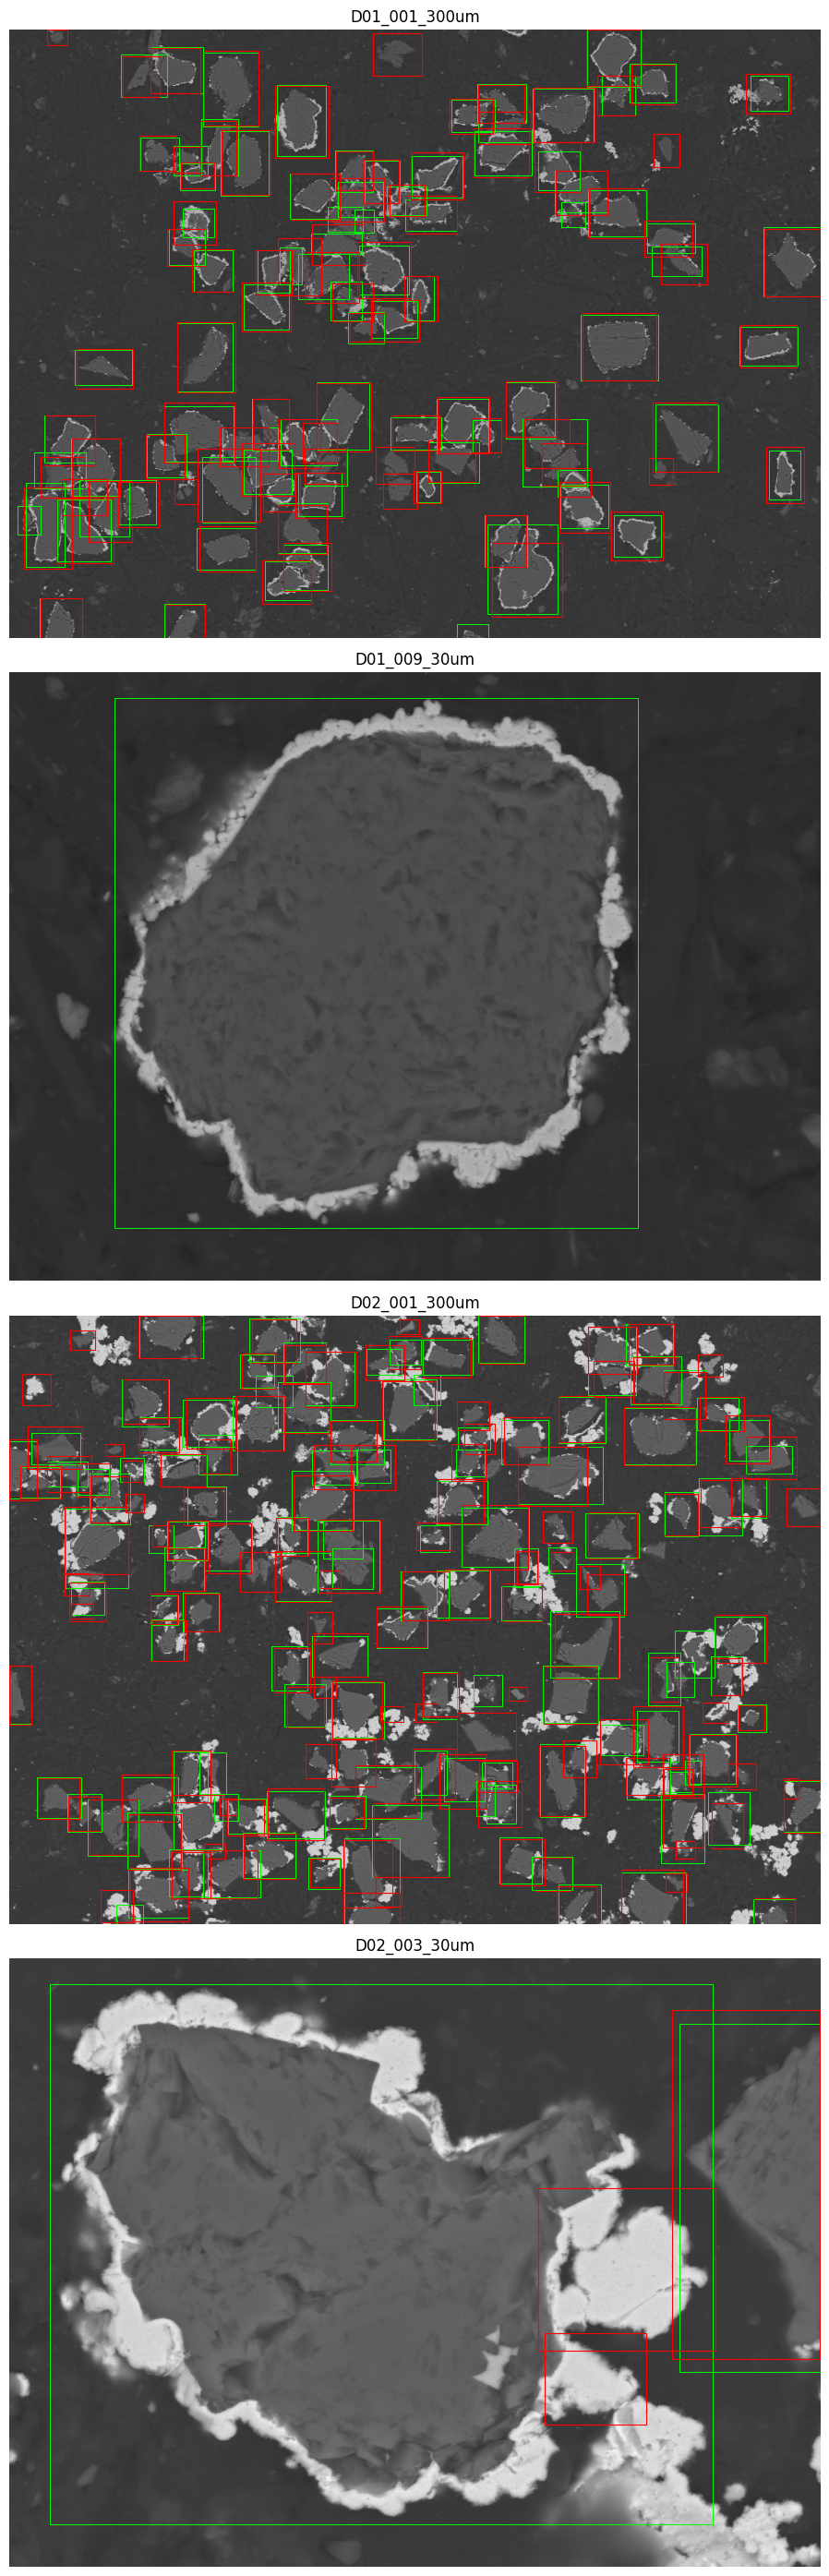

Pipeline: models\recall90_20261024\detection\selected_pipeline.json


In [8]:
preview = [r for r in records if r['split'] == 'val']
fig, axes = plt.subplots(len(preview), 1, figsize=(14, 7 * len(preview)), squeeze=False)
for ax, sample in zip(axes.flat, preview):
    ax.imshow(Image.open(sample['path']))
    for box in sample['boxes']:
        ax.add_patch(Rectangle(box[:2], *(box[2:] - box[:2]), fill=False, color='lime', linewidth=.7))
    for box in prediction_cache[selected.variant][sample['image_id']]:
        if box[4] >= COUNT_CONF:
            ax.add_patch(Rectangle(box[:2], *(box[2:4] - box[:2]), fill=False, color='red', linewidth=.8))
    ax.set_title(sample['image_id'])
    ax.axis('off')
plt.tight_layout()
plt.savefig(OUT / 'val_selected_overlays.jpg', dpi=120, bbox_inches='tight')
plt.show()
print('Pipeline:', (OUT / 'selected_pipeline.json').relative_to(ROOT))

## Результаты

Val: precision 80.4%, recall 90.1%. Test: precision 73.2%, recall 92.1%.
Полнота ≥90% достигнута суммарно. На val recall крупных bbox — 50%, мелких — 25%; на одном крупноплановом test-кадре — 0 из 1.
Качество зависит от увеличения, остаются ложные рамки и пропуски.
`clear50` и `fresh50` содержат одинаковые веса и соответствуют одному базовому результату.


## 8. Добавление синтетики

Сравнение реального train и того же набора с 20 синтетическими кадрами.
Параметры обучения и предсказания совпадают; число шагов зависит от размера train.
Оценка на real-val при общем пороге и при подборе порога для recall ≥0.90.
Для реального набора используются готовые веса; test повторно не оценивается.


In [9]:
RUN_SYNTHETIC_EXPERIMENT = True

if RUN_SYNTHETIC_EXPERIMENT:
    synthetic = ROOT / 'models/recall90_20261024/synthetic'
    synthetic_images = sorted((synthetic / 'images').glob('*.png'))
    if len(synthetic_images) != 20:
        raise ValueError('Контрольный опыт рассчитан на 20 синтетических изображений.')
    syn_digest = hashlib.sha256()
    for image_path in synthetic_images:
        label = synthetic / 'labels' / f'{image_path.stem}.txt'
        rows = np.loadtxt(label, ndmin=2).reshape(-1, 5)
        if not len(rows) or not np.isfinite(rows).all() or (rows[:, 0] != 0).any():
            raise ValueError(f'Неверные синтетические labels: {label}')
        if (rows[:, 3:] <= 0).any() or (rows[:, 1:3] - rows[:, 3:] / 2 < -1e-6).any() or (rows[:, 1:3] + rows[:, 3:] / 2 > 1 + 1e-6).any():
            raise ValueError(f'Рамка за пределами кадра: {label}')
        syn_digest.update(image_path.read_bytes())
        syn_digest.update(label.read_bytes())
    controlled = OUT / 'synthetic_control'
    controlled.mkdir(exist_ok=True)
    # Профиль выбирается только по real-val среди новых обучений.
    new_candidates = candidates.loc[candidates.model.isin(PROFILES)]
    feasible_new = new_candidates.loc[new_candidates.recall >= TARGET_RECALL]
    best_new = feasible_new.sort_values(['precision', 'recall'], ascending=False).iloc[0] if len(feasible_new) else new_candidates.sort_values(['recall', 'precision'], ascending=False).iloc[0]
    profile_name = best_new.model
    profile = PROFILES[profile_name]
    control_metadata = dict(real_data_sha256=DATA_HASH, synthetic_sha256=syn_digest.hexdigest(),
        synthetic_images=len(synthetic_images), profile=profile_name, train_args=profile,
        inference_pipeline=pipeline, seed=SEED,
        generation_manifest='models/recall90_20261024/synthetic/generation_manifest.json',
        annotation_status='assistant_visual_reviewed_20_frames',
        real_control_weights=(OUT / profile_name / 'weights/best.pt').relative_to(ROOT).as_posix())
    control_manifest = controlled / 'manifest.json'
    if control_manifest.exists() and json.loads(control_manifest.read_text(encoding='utf-8')) != control_metadata:
        raise ValueError('Параметры/данные изменились; нужен новый каталог контрольного опыта.')
    control_manifest.write_text(json.dumps(control_metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    control_rows = []
    for dataset in ('real', 'mixed'):
        train_paths = [r['path'] for r in records if r['split'] == 'train']
        if dataset == 'mixed':
            train_paths += synthetic_images
        train_list = controlled / f'{dataset}_train.txt'
        train_list.write_text('\n'.join(p.resolve().as_posix() for p in train_paths) + '\n', encoding='utf-8')
        config = controlled / f'{dataset}.yaml'
        config.write_text(yaml.safe_dump(dict(path=DATA.as_posix(), train=train_list.as_posix(),
            val=(DATA / 'images/val').as_posix(), names={0: 'particle'})), encoding='utf-8')
        name = f'synthetic_control/{dataset}_{profile_name}'
        weights = OUT / profile_name / 'weights/best.pt' if dataset == 'real' else OUT / name / 'weights/best.pt'
        if not weights.exists():
            weights, status = train_detector(INITIAL_WEIGHTS, name, TRAIN_MINUTES,
                data=str(config), **profile)
            if status['status'] == 'time_limited':
                weights, status = train_detector(weights, f'{name}_fallback', FALLBACK_MINUTES,
                    data=str(config), epochs=25, patience=8, imgsz=768, batch=4, nbs=16)
        detector = YOLO(str(weights), task='detect')
        predictions = {r['image_id']: predict_frame(detector, r['path'], chosen_tile,
            selected.preprocessing, int(selected.imgsz)) for r in records if r['split'] == 'val'}
        values, frames, _ = evaluate_predictions(predictions, 'val')
        point = select_point(confidence_curve(predictions))
        control_rows.append(dict(dataset=dataset, profile=profile_name, train_images=len(train_paths),
            weights=weights.relative_to(ROOT).as_posix(), real_control_reused=dataset == 'real',
            common_confidence=COUNT_CONF,
            precision=values['precision'], recall=values['recall'], map50_95=values['map50_95'],
            target_confidence=float(point.confidence), target_precision=float(point.precision),
            target_recall=float(point.recall)))
        frames.to_csv(controlled / f'val_{dataset}_frames.csv', index=False)
        del detector
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    control_results = pd.DataFrame(control_rows)
    control_results.to_csv(controlled / 'val_comparison.csv', index=False)
    display(control_results.round(4))

New https://pypi.org/project/ultralytics/8.4.186 available  Update with 'pip install -U ultralytics'


Ultralytics 8.4.24  Python-3.10.6 torch-2.9.1+cu128 CUDA:0 (NVIDIA GeForce RTX 5070, 12199MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=0, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\models\recall90_20261024\detection\synthetic_control\mixed.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=1000, mixup=0.0, mode=train, model=C:\games\!!!studyMaga\2026\PP_Particles\PP_Particles\research\yolo26s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=mixed_detail1280_light, nbs=64, nms=False, opset=No

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


...

YOLO26s summary (fused): 122 layers, 9,465,567 parameters, 0 gradients, 20.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 9.0it/s 0.1s

                   all          4        223      0.821      0.637       0.75      0.451


Speed: 0.3ms preprocess, 6.4ms inference, 0.0ms loss, 0.4ms postprocess per image


,dataset,profile,train_images,weights,real_control_reused,common_confidence,precision,recall,map50_95,target_confidence,target_precision,target_recall
0,real,detail1280_light,24,models/recall90_20261024/detection/detail1280_...,True,0.4132,0.8040,0.9013,0.5665,0.4132,0.8040,0.9013
1,mixed,detail1280_light,44,models/recall90_20261024/detection/synthetic_c...,False,0.4132,0.8596,0.6592,0.4892,0.0375,0.3736,0.9013


## Результат сравнения

При общем пороге recall после добавления синтетики падает с 90.1% до 65.9%.
При подборе порога для recall ≈90% precision составляет 37.4% против 80.4% на реальном наборе.
Для пайплайна выбрана модель без синтетики.


In [10]:
synthetic_summary = pd.read_csv(OUT / 'synthetic_control/val_comparison.csv')
display(synthetic_summary[['dataset', 'train_images', 'precision', 'recall', 'map50_95',
    'target_confidence', 'target_precision', 'target_recall']].round(4))

,dataset,train_images,precision,recall,map50_95,target_confidence,target_precision,target_recall
0,real,24,0.8040,0.9013,0.5665,0.4132,0.8040,0.9013
1,mixed,44,0.8596,0.6592,0.4892,0.0375,0.3736,0.9013
